# 05 — DBSCAN Baseline

Density-based clustering of Dubai Metro station-window behaviour using the shared, standardized feature table stored in S3.

**Workflow:** Load features → PCA → DBSCAN implementation → scikit-learn comparison → parameter selection → clustering diagnostics → station-level stability → export results.

**Input:** `s3://dubai-metro-profiling-<account-id>/curated/features/`  
**Output:** `results/labels/dbscan.parquet`

In [1]:
import os
import boto3
import awswrangler as wr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import deque
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score,
)

SEED = 0
rng = np.random.default_rng(SEED)

def find_project_root():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        if (folder / 'notebooks').is_dir() and (folder / 'README.md').is_file():
            return folder
    raise FileNotFoundError(f'Project root not found from {here}.')

ROOT = find_project_root()
HAND_LABELS_PATH = ROOT / 'results/hand_labels.csv'
REQUIRED_KEYS = ['win', 'location_id', 'station']
AUXILIARY_COLUMNS = ['timed_taps', 'check_ins', 'check_outs']
FEATURE_COLS = None
USE_PCA = True
PCA_VARIANCE = 0.90

# AWS configuration follows the active CLI profile and allows cross-account bucket selection.
AWS_PROFILE = os.environ.get('AWS_PROFILE') or None
AWS_REGION = os.environ.get('AWS_REGION') or os.environ.get('AWS_DEFAULT_REGION') or 'ap-south-1'
session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)
ACCOUNT_ID = session.client('sts').get_caller_identity()['Account']
BUCKET = os.environ.get('METRO_S3_BUCKET') or f'dubai-metro-profiling-{ACCOUNT_ID}'
FEATURES_S3 = f's3://{BUCKET}/curated/features/'

print('Project root:', ROOT)
print('AWS profile:', AWS_PROFILE or 'default')
print('AWS region:', AWS_REGION)
print('Feature source:', FEATURES_S3)

Matplotlib is building the font cache; this may take a moment.


Project root: /Users/aryanchandra/Desktop/Data-Mining-MetroStations-profiling-main2
AWS profile: metro-aryan
AWS region: ap-south-1
Feature source: s3://dubai-metro-profiling-750240012171/curated/features/


## 1. Load and validate features

Read the standardized feature table directly from S3 using the current AWS profile, preserve station-window identifiers, and select the numerical clustering features. Sort by `win` and `location_id` for consistent label alignment.

In [2]:
try:
    df = wr.s3.read_parquet(path=FEATURES_S3, boto3_session=session)
except Exception as exc:
    raise RuntimeError(
        f'Unable to read the shared feature data from {FEATURES_S3} '
        f'using AWS profile {AWS_PROFILE or "default"} in {AWS_REGION}. '
        'Check the bucket account, region, and S3 permissions.'
    ) from exc

missing = sorted(set(REQUIRED_KEYS) - set(df.columns))
if missing:
    raise ValueError(f'Input is missing required station-window identifiers: {missing}')

# Make row order deterministic across machines, including ambiguous border assignments.
if df.duplicated(['win', 'location_id']).any():
    raise ValueError('Duplicate (win, location_id) keys: inspect the feature pipeline before clustering.')
df = df.sort_values(['win', 'location_id'], kind='stable').reset_index(drop=True)

if FEATURE_COLS is None:
    feat_cols = [name for name in df.columns if name not in REQUIRED_KEYS + AUXILIARY_COLUMNS]
else:
    feat_cols = list(FEATURE_COLS)
    missing_features = sorted(set(feat_cols) - set(df.columns))
    if missing_features:
        raise ValueError(f'Configured features not found: {missing_features}')

bad_types = [name for name in feat_cols if not pd.api.types.is_numeric_dtype(df[name])]
if bad_types:
    raise ValueError(f'Non-numeric columns included as features: {bad_types}. Explicitly configure FEATURE_COLS.')

X = df[feat_cols].to_numpy(dtype=np.float64)
print('Input table:', df.shape, '| numeric feature matrix:', X.shape)
print('Feature names:', feat_cols)
if X.shape != (244, 17):
    raise ValueError(f'Expected 244 rows x 17 features per current work plan, got {X.shape}. '
                     'Check the input table and feature column selection.')
if not np.isfinite(X).all():
    raise ValueError('Features contain NaNs or infinities; repair the shared feature table before clustering.')

print('Feature means (first five):', np.round(X.mean(axis=0)[:5], 3))
print('Feature stds  (first five):', np.round(X.std(axis=0)[:5], 3))
print('Feature values loaded without additional scaling.')

Input table: (244, 23) | numeric feature matrix: (244, 17)
Feature names: ['check_in_share_00_07', 'check_in_share_07_10', 'check_in_share_10_16', 'check_in_share_16_20', 'check_in_share_20_24', 'check_out_share_00_07', 'check_out_share_07_10', 'check_out_share_10_16', 'check_out_share_16_20', 'check_out_share_20_24', 'net_flow_00_07', 'net_flow_07_10', 'net_flow_10_16', 'net_flow_16_20', 'net_flow_20_24', 'weekend_share', 'volume_share']
Feature means (first five): [-0.  0.  0. -0.  0.]
Feature stds  (first five): [1. 1. 1. 1. 1.]
Feature values loaded without additional scaling.


## 2. PCA 

PCA provides a lower-dimensional representation of the correlated behavioural features. The number of retained components is determined from the cumulative explained variance. The `USE_PCA` setting controls whether DBSCAN uses this representation or the original feature matrix.


PCA: 5 / 17 components; retained variance 90.862%


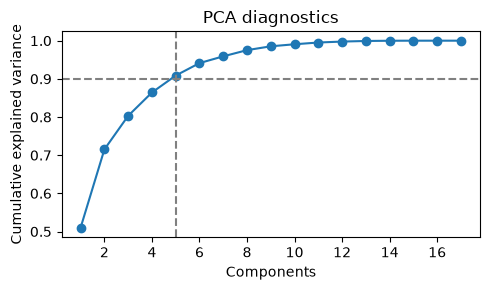

                         PC1    PC2    PC3    PC4    PC5
check_in_share_00_07   0.279 -0.078 -0.169 -0.059  0.511
check_in_share_07_10   0.306 -0.125 -0.216  0.063  0.122
check_in_share_10_16   0.119 -0.156  0.478  0.596 -0.133
check_in_share_16_20  -0.317 -0.085 -0.092 -0.118 -0.242
check_in_share_20_24  -0.038  0.463  0.195 -0.265  0.157
check_out_share_00_07 -0.145 -0.295  0.244 -0.355  0.518
check_out_share_07_10 -0.306 -0.149 -0.219  0.079 -0.051
check_out_share_10_16 -0.121  0.387  0.184  0.448  0.276
check_out_share_16_20  0.301  0.157 -0.028 -0.070 -0.144
check_out_share_20_24  0.290 -0.099  0.181 -0.230 -0.126
net_flow_00_07         0.283  0.152 -0.238  0.206  0.181
net_flow_07_10         0.329 -0.039  0.011 -0.016  0.098
net_flow_10_16         0.118 -0.451  0.167 -0.003 -0.088
net_flow_16_20        -0.324 -0.123 -0.011 -0.004  0.038
net_flow_20_24        -0.263  0.267  0.003  0.023  0.223
weekend_share          0.124  0.239  0.524 -0.324 -0.188
volume_share           0.126  0

In [9]:
if USE_PCA:
    pca_full = PCA(random_state=SEED).fit(X)
    cum = np.cumsum(pca_full.explained_variance_ratio_)
    n_comp = int(np.searchsorted(cum, PCA_VARIANCE) + 1)
    pca = PCA(n_components=n_comp, random_state=SEED)
    Z = pca.fit_transform(X)
    print(f'PCA: {n_comp} / {len(feat_cols)} components; retained variance {cum[n_comp-1]:.3%}')
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(range(1, len(cum) + 1), cum, marker='o')
    ax.axhline(PCA_VARIANCE, ls='--', c='grey')
    ax.axvline(n_comp, ls='--', c='grey')
    ax.set(xlabel='Components', ylabel='Cumulative explained variance', title='PCA diagnostics')
    plt.tight_layout()
    plt.show()
else:
    n_comp = X.shape[1]
    Z = X.copy()
    print(f'PCA disabled; clustering on all {X.shape[1]} numeric features.')
loadings = pd.DataFrame(
    pca.components_.T,
    index=feat_cols,
    columns=[f"PC{i+1}" for i in range(n_comp)]
)

print(loadings.round(3))


## 3. DBSCAN implementation and scikit-learn comparison

A core point has at least `min_samples` observations, including itself, within `eps`. Core points expand density-connected clusters; border points join neighbouring clusters; noise points receive label `-1`.

Cluster labels are compared with scikit-learn using partition agreement, which allows for different numeric cluster IDs.


In [10]:

import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Prepare the feature matrix
if "X" not in globals():
    raise RuntimeError("Run the AWS feature-loading cell first.")

if "Z" not in globals():
    if USE_PCA:
        pca = PCA(n_components=PCA_VARIANCE, svd_solver="full")
        Z = pca.fit_transform(X)
    else:
        Z = np.asarray(X, dtype=float)

Z = np.asarray(Z, dtype=float)

if Z.ndim != 2 or not np.isfinite(Z).all():
    raise ValueError("Invalid feature matrix.")

print("DBSCAN input shape:", Z.shape)


# DBSCAN implementation from scratch
def dbscan_scratch(data, eps, min_samples):

    if eps <= 0:
        raise ValueError("eps must be positive.")

    if min_samples < 1:
        raise ValueError("min_samples must be at least 1.")

    data = np.asarray(data, dtype=float)
    n = len(data)

    # Calculate pairwise Euclidean distances
    distances = np.linalg.norm(
        data[:, None, :] - data[None, :, :],
        axis=2
    )

    # Find neighbours within eps
    neighbors = [
        np.flatnonzero(distances[i] <= eps)
        for i in range(n)
    ]

    # Identify core points
    core_points = np.array([
        len(neighbors[i]) >= min_samples
        for i in range(n)
    ])

    # Initially assign all points as noise
    labels = np.full(n, -1, dtype=int)

    cluster_id = 0

    # Expand clusters from core points
    for i in range(n):

        if labels[i] != -1 or not core_points[i]:
            continue

        stack = [i]

        while stack:
            point = stack.pop()

            if labels[point] != -1:
                continue

            labels[point] = cluster_id

            if core_points[point]:
                for neighbor in neighbors[point]:
                    if labels[neighbor] == -1:
                        stack.append(int(neighbor))

        cluster_id += 1

    return labels


# Compare clustering assignments
def same_partition(a, b):

    a = np.asarray(a)
    b = np.asarray(b)

    same_noise = np.array_equal(
        a == -1,
        b == -1
    )

    ari = adjusted_rand_score(a, b)

    return same_noise and np.isclose(
        ari, 1.0, atol=1e-12
    )


# Test against scikit-learn DBSCAN
test_parameters = [
    (1.5, 5),
    (2.0, 5),
    (2.5, 8)
]

for eps, min_samples in test_parameters:

    # Custom implementation
    scratch_labels = dbscan_scratch(
        Z,
        eps=eps,
        min_samples=min_samples
    )

    # Scikit-learn implementation
    sklearn_labels = DBSCAN(
        eps=eps,
        min_samples=min_samples
    ).fit_predict(Z)

    # Verify clustering agreement
    match = same_partition(
        scratch_labels,
        sklearn_labels
    )

    # Calculate clusters and noise
    n_clusters = len(
        set(scratch_labels) - {-1}
    )

    n_noise = int(
        np.sum(scratch_labels == -1)
    )

    print(
        f"eps={eps}, "
        f"min_samples={min_samples} | "
        f"Match={match} | "
        f"Clusters={n_clusters} | "
        f"Noise={n_noise}"
    )


DBSCAN input shape: (244, 5)
eps=1.5, min_samples=5 | Match=True | Clusters=5 | Noise=47
eps=2.0, min_samples=5 | Match=True | Clusters=4 | Noise=6
eps=2.5, min_samples=8 | Match=True | Clusters=1 | Noise=6


## 4. Parameter selection

The k-distance curves illustrate neighbourhood scales. Candidate `eps` values are evaluated over quantiles of the k-distance distribution for several `min_samples` values.

The selection criterion uses silhouette score among candidates with 2–10 clusters and noise below 20%. Internal metrics are computed on non-noise observations and are reported alongside noise fraction and coverage.


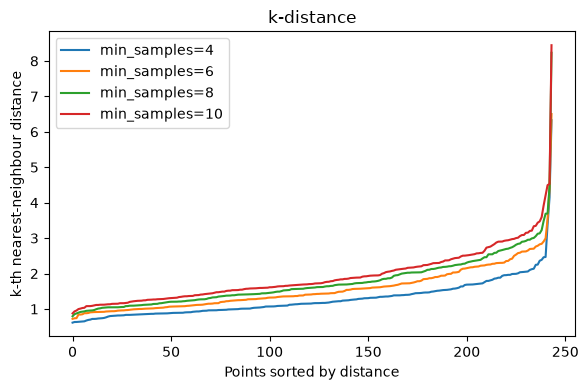

In [11]:
def kdist(data, k):
    # Explicit X queries include each query point itself, matching DBSCAN's definition.
    d, _ = NearestNeighbors(n_neighbors=k).fit(data).kneighbors(data)
    return np.sort(d[:, -1])

fig, ax = plt.subplots(figsize=(6, 4))
for k in [4, 6, 8, 10]:
    ax.plot(kdist(Z, k), label=f'min_samples={k}')
ax.set(xlabel='Points sorted by distance', ylabel='k-th nearest-neighbour distance', title='k-distance')
ax.legend()
plt.tight_layout()
plt.show()


In [12]:
def evaluate(data, lab):
    mask = lab != -1
    k = len(np.unique(lab[mask]))
    sizes = pd.Series(lab[mask]).value_counts() if mask.any() else pd.Series(dtype=int)
    result = dict(k=int(k), noise=float(1 - mask.mean()), coverage=float(mask.mean()),
                  smallest_cluster=int(sizes.min()) if len(sizes) else 0,
                  largest_cluster_share=float(sizes.max() / mask.sum()) if len(sizes) else 0.0)
    if 2 <= k < mask.sum():
        result.update(sil=float(silhouette_score(data[mask], lab[mask])),
                      dbi=float(davies_bouldin_score(data[mask], lab[mask])),
                      ch=float(calinski_harabasz_score(data[mask], lab[mask])))
    else:
        result.update(sil=np.nan, dbi=np.nan, ch=np.nan)
    return result

rows = []
for ms in range(4, 11):
    distances = kdist(Z, ms)
    # Numeric eps candidates: the k-distance curve itself guides the sweep.
    for eps in np.unique(np.round(np.quantile(distances, np.linspace(0.30, 0.99, 20)), 6)):
        if eps <= 0:
            continue
        candidate_labels = DBSCAN(eps=float(eps), min_samples=ms).fit_predict(Z)
        rows.append(dict(min_samples=ms, eps=float(eps), **evaluate(Z, candidate_labels)))

grid = pd.DataFrame(rows)
if grid.empty:
    raise RuntimeError('Parameter sweep produced no positive eps candidates. Inspect repeated/constant features.')

ok = grid.loc[grid.k.between(2, 10) & (grid.noise < 0.20) & grid.sil.notna()].copy()
ok = ok.sort_values(['sil', 'coverage'], ascending=[False, False])
print(f'{len(ok)} of {len(grid)} parameter combinations pass the explicit filter')
display(ok.head(10) if not ok.empty else grid.sort_values('noise').head(10))


29 of 140 parameter combinations pass the explicit filter


,min_samples,eps,k,noise,coverage,smallest_cluster,largest_cluster_share,sil,dbi,ch
111,9,2.087821,2,0.135246,0.864754,7,0.966825,0.296732,0.776268,21.013558
18,4,2.090672,2,0.012295,0.987705,5,0.979253,0.285158,0.726947,13.085437
10,4,1.360426,9,0.196721,0.803279,4,0.739796,0.156925,0.800721,27.151226
114,9,2.337518,2,0.036885,0.963115,7,0.970213,0.151809,1.132895,8.893724
11,4,1.399248,8,0.180328,0.819672,4,0.765000,0.142925,0.805928,28.147216
54,6,2.075345,2,0.061475,0.938525,9,0.960699,0.138797,1.231594,10.149388
94,8,2.254170,2,0.045082,0.954918,9,0.961373,0.134215,1.237091,10.035653
113,9,2.260216,2,0.045082,0.954918,9,0.961373,0.134215,1.237091,10.035653
52,6,1.845158,2,0.151639,0.848361,8,0.961353,0.131035,1.226502,8.742915
34,5,1.866073,3,0.106557,0.893443,5,0.931193,0.128246,1.055293,13.631807


In [13]:
if ok.empty:
    raise RuntimeError(
        'No parameter combination passed the stated constraints (2–10 clusters, <20% noise). '
        'Inspect the grid and k-distance curves; adjust the selection criteria if justified.'
    )

best = ok.iloc[0]
EPS, MS = float(best.eps), int(best.min_samples)

# Generate final assignments with the from-scratch implementation.
labels = dbscan_scratch(Z, EPS, MS)
reference_labels = DBSCAN(eps=EPS, min_samples=MS).fit_predict(Z)
if not same_partition(labels, reference_labels):
    raise AssertionError('Scratch/scikit-learn partitions differ at chosen settings. '
                         'Check core/border handling and partition agreement.')

res = evaluate(Z, labels)
print(f'Selected eps={EPS:.6f}, min_samples={MS}; scratch matches sklearn exactly up to cluster ID names')
print({key: (round(val, 4) if isinstance(val, float) else val) for key, val in res.items()})
if res['largest_cluster_share'] > 0.85 or res['smallest_cluster'] < 0.05 * len(df):
    print('Cluster-size diagnostic: largest cluster exceeds 85% of assigned rows or a cluster is below 5% of all rows.')
print('Metric scope: exploratory scores calculated on the parameter-selection dataset.')


Selected eps=2.087821, min_samples=9; scratch matches sklearn exactly up to cluster ID names
{'k': 2, 'noise': 0.1352, 'coverage': 0.8648, 'smallest_cluster': 7, 'largest_cluster_share': 0.9668, 'sil': 0.2967, 'dbi': 0.7763, 'ch': 21.0136}
Cluster-size diagnostic: largest cluster exceeds 85% of assigned rows or a cluster is below 5% of all rows.
Metric scope: exploratory scores calculated on the parameter-selection dataset.


## 5. Cluster distribution and noise analysis

Summarize cluster sizes, noise fraction, and the station-windows assigned to noise. Silhouette, Davies–Bouldin, and Calinski–Harabasz metrics describe only the non-noise subset.


In [16]:
out = df[REQUIRED_KEYS].copy()
out['cluster'] = labels
print('Cluster sizes (noise is -1):\n', out.cluster.value_counts().sort_index().to_string())
noise_by_station = (out.assign(is_noise=out.cluster.eq(-1))
                    .groupby('station', dropna=False)
                    .agg(windows=('win','size'), noise_windows=('is_noise','sum'))
                    .query('noise_windows > 0')
                    .sort_values('noise_windows', ascending=False))
display(noise_by_station)


Cluster sizes (noise is -1):
 cluster
-1     33
 0    204
 1      7


,windows,noise_windows
station,,
Airport Terminal 3,5,5
Burj Khalifa/ Dubai Mall,5,5
Airport Terminal 1,5,4
Al Ras,5,4
Energy,4,4
Creek,5,2
Jabal Ali,3,2
Al Furjan,2,1
Al Jadaf,5,1


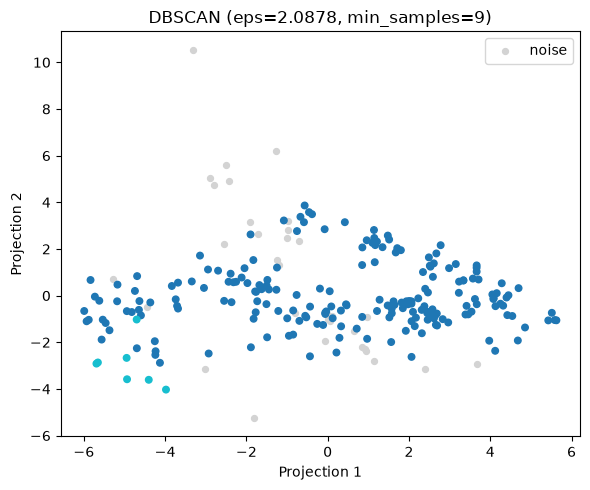

Saved figure: /Users/aryanchandra/Desktop/Data-Mining-MetroStations-profiling-main2/figures/dbscan_clusters.png


In [17]:
projection = PCA(n_components=2, random_state=SEED).fit_transform(Z) if Z.shape[1] > 1 else np.column_stack([Z[:, 0], np.zeros(len(Z))])
fig, ax = plt.subplots(figsize=(6, 5))
noise = labels == -1
ax.scatter(projection[noise, 0], projection[noise, 1], c='lightgrey', s=18, label='noise')
if (~noise).any():
    ax.scatter(projection[~noise, 0], projection[~noise, 1], c=labels[~noise], cmap='tab10', s=22)
ax.set(xlabel='Projection 1', ylabel='Projection 2',
       title=f'DBSCAN (eps={EPS:.4f}, min_samples={MS})')
ax.legend()
plt.tight_layout()
figure_path = ROOT / 'figures/dbscan_clusters.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(figure_path, dpi=150)
plt.show()
print('Saved figure:', figure_path)


## 6. Station-grouped subsampling stability

Each replicate retains 80% of station identities with all their corresponding windows. Refit DBSCAN on that subset and calculate adjusted Rand index (ARI) against the reference clustering on the same retained observations.

The PCA embedding remains fixed across replicates; the resulting ARI describes sensitivity to station subsampling.


In [18]:
stations = df['station'].to_numpy()
uniq = np.unique(stations)
if len(uniq) < 3:
    raise ValueError('Station-grouped stability needs at least three distinct stations.')
aris = []
for _ in range(100):
    keep = rng.choice(uniq, size=max(2, int(0.8 * len(uniq))), replace=False)
    m = np.isin(stations, keep)
    sub = dbscan_scratch(Z[m], eps=EPS, min_samples=MS)
    aris.append(adjusted_rand_score(labels[m], sub))
aris = np.asarray(aris)
print(f'ARI stability from 100 station-grouped subsamples: mean={aris.mean():.3f}; sd={aris.std():.3f}')
print('Range:', round(aris.min(),3), 'to', round(aris.max(),3))


ARI stability from 100 station-grouped subsamples: mean=0.870; sd=0.092
Range: 0.527 to 1.0


## 7. Validation labels and result export

Where available, the manually labelled stations are compared with the discovered clusters as a qualitative check. The final output uses the agreed schema:

`win, location_id, station, method, eps, min_samples, pca_components, cluster`


In [19]:
if HAND_LABELS_PATH.is_file():
    hand = pd.read_csv(HAND_LABELS_PATH)
    st_col = next((col for col in hand.columns if col.lower() in ('station','station_name')), None)
    type_col = next((col for col in hand.columns if 'type' in col.lower() or 'label' in col.lower()), None)
    if st_col is None or type_col is None:
        print('Hand-label columns not recognized; skipped comparison. Columns:', list(hand.columns))
    else:
        if hand[st_col].duplicated().any():
            print('Hand-label table has repeated stations; inspect duplicates before interpreting match.')
        else:
            chk = (out.merge(hand[[st_col, type_col]], left_on='station', right_on=st_col)
                     .groupby([type_col,'station']).cluster.agg(lambda s: sorted(set(s))).reset_index())
            print(f'Hand labelled stations: {hand[st_col].nunique()}; matched: {chk.station.nunique()}')
            display(chk)
else:
    print('Hand-label comparison skipped; missing:', HAND_LABELS_PATH)

out['method'] = 'dbscan'
out['eps'] = EPS
out['min_samples'] = MS
out['pca_components'] = n_comp if USE_PCA else 0
output_cols = ['win','location_id','station','method','eps','min_samples','pca_components','cluster']
output = out[output_cols].copy()
assert len(output) == len(df)
assert not output.duplicated(['win','location_id']).any()
assert output['cluster'].notna().all()

label_path = ROOT / 'results/labels/dbscan.parquet'
label_path.parent.mkdir(parents=True, exist_ok=True)
try:
    output.to_parquet(label_path, index=False)
except ImportError as e:
    raise ImportError('Writing Parquet requires pyarrow: python -m pip install pyarrow') from e

# Verify the written artifact is readable and preserves station-window alignment.
roundtrip = pd.read_parquet(label_path)
pd.testing.assert_frame_equal(output.reset_index(drop=True), roundtrip.reset_index(drop=True), check_dtype=True)
print(f'Wrote and read back {len(output)} rows:', label_path)

summary = dict(method='dbscan', eps=EPS, min_samples=MS,
               pca_components=n_comp if USE_PCA else 0, **res,
               stability_ari_mean=float(aris.mean()), stability_ari_sd=float(aris.std()))
summary_path = ROOT / 'results/dbscan/summary.csv'
summary_path.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame([summary]).to_csv(summary_path, index=False)
print('Saved summary:', summary_path)
display(pd.Series(summary))


Hand labelled stations: 12; matched: 12


,expected_type,station,cluster
0,Airport,Airport Terminal 3,[-1]
1,Business,Dubai Healthcare City,[0]
2,Business,Financial Centre,[0]
3,Education,Oud Metha,[0]
4,Mixed,Al Rigga,[0]
5,Mixed,DMCC,[0]
6,Residential,Stadium,[0]
7,Shopping and leisure,EXPO,"[-1, 0]"
8,Shopping and leisure,Ibn Battuta,"[-1, 0]"
9,Shopping and leisure,Mall of the Emirates,[0]


Wrote and read back 244 rows: /Users/aryanchandra/Desktop/Data-Mining-MetroStations-profiling-main2/results/labels/dbscan.parquet
Saved summary: /Users/aryanchandra/Desktop/Data-Mining-MetroStations-profiling-main2/results/dbscan/summary.csv


method                      dbscan
eps                       2.087821
min_samples                      9
pca_components                   5
k                                2
noise                     0.135246
coverage                  0.864754
smallest_cluster                 7
largest_cluster_share     0.966825
sil                       0.296732
dbi                       0.776268
ch                       21.013558
stability_ari_mean        0.870009
stability_ari_sd          0.092043
dtype: object

## Experiment summary

Record the feature dimensions, retained PCA components, selected `eps` and `min_samples`, cluster sizes, noise fraction, coverage, internal evaluation metrics, and station-grouped ARI stability.

**Generated artifacts**
- `results/labels/dbscan.parquet` — station-window cluster assignments and model settings
- `results/dbscan/summary.csv` — selected parameters and evaluation statistics
- `figures/dbscan_clusters.png` — 2D visualization of the resulting clusters
